In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict

from src.drift.lepski_window_selector import LepskiWindowSelector
from src.conformal.nonconformity_scores import compute_aps_scores

plt.style.use('seaborn-v0_8-paper')
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 14,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.autolayout': True
})

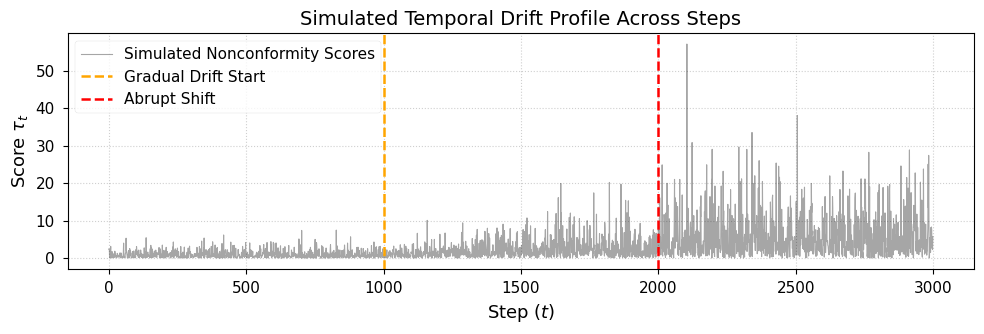

In [5]:
def generate_drifting_score_stream(n_steps: int = 3000, seed: int = 42) -> np.ndarray:
    """
    Simulates a non-stationary stream of nonconformity scores:
    - Phase 1 (0 to 1000): Stationary regime.
    - Phase 2 (1000 to 2000): Gradual drift (scores increase).
    - Phase 3 (2000 to 3000): Sudden regime shift / severe drift.
    """
    rng = np.random.default_rng(seed)
    scores = np.zeros(n_steps)
    
    scores[:1000] = rng.exponential(scale=1.0, size=1000)
    
    drift_trend = np.linspace(1.0, 3.5, 1000)
    scores[1000:2000] = rng.exponential(scale=drift_trend, size=1000)
    
    scores[2000:] = rng.exponential(scale=6.0, size=1000)
    
    return scores

scores_stream = generate_drifting_score_stream()

plt.figure(figsize=(10, 3.5))
plt.plot(scores_stream, color='black', alpha=0.35, lw=0.8, label="Simulated Nonconformity Scores")
plt.axvline(1000, color='orange', linestyle='--', lw=1.8, label="Gradual Drift Start")
plt.axvline(2000, color='red', linestyle='--', lw=1.8, label="Abrupt Shift")
plt.title("Simulated Temporal Drift Profile Across Steps")
plt.xlabel("Step ($t$)")
plt.ylabel("Score $\\tau_t$")
plt.legend(loc="upper left")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [6]:
alpha = 0.10
target_coverage = 1.0 - alpha
candidate_windows = [64, 128, 256, 512, 1024]
selector = LepskiWindowSelector(alpha=alpha, delta=0.05)

step_eval_indices = range(1050, len(scores_stream), 20)
results = []

for t in step_eval_indices:
    history = scores_stream[:t]
    
    cand_scores = [history[-w:] for w in candidate_windows if len(history) >= w]
    cand_sizes = [w for w in candidate_windows if len(history) >= w]
    
    best_idx, q_adaptive, diag = selector.select_best_window(cand_scores, cand_sizes)
    selected_k = cand_sizes[best_idx]
    
    q_fixed_small = np.quantile(history[-64:], target_coverage)
    q_fixed_large = np.quantile(history[-1024:], target_coverage)
    
    if t < 1000:
        scale_t = 1.0
    elif t < 2000:
        scale_t = 1.0 + 2.5 * ((t - 1000) / 1000.0)
    else:
        scale_t = 6.0
        
    cov_adaptive = 1.0 - np.exp(-q_adaptive / scale_t)
    cov_fixed_small = 1.0 - np.exp(-q_fixed_small / scale_t)
    cov_fixed_large = 1.0 - np.exp(-q_fixed_large / scale_t)
    
    results.append({
        "step": t,
        "selected_k": selected_k,
        "bias_proxy": diag["bias_proxy"][best_idx],
        "variance_penalty": diag["variance_penalty"][best_idx],
        "cov_adaptive": cov_adaptive,
        "cov_fixed_small": cov_fixed_small,
        "cov_fixed_large": cov_fixed_large
    })

df_eval = pd.DataFrame(results)

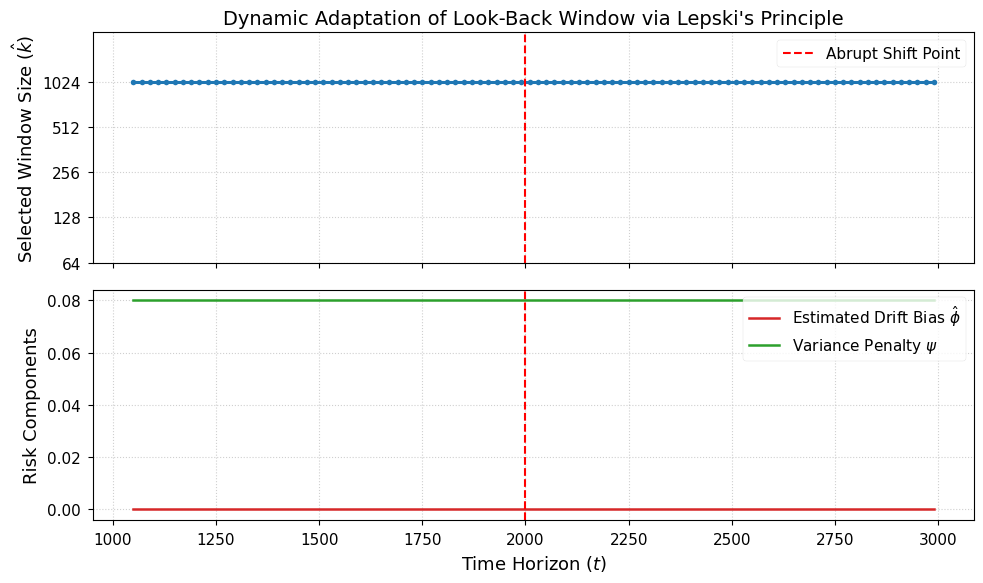

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

# الرسم الأول: حجم النافذة المختارة
ax1.plot(df_eval["step"], df_eval["selected_k"], color='#1f77b4', lw=2.2, marker='o', ms=4)
ax1.axvline(2000, color='red', linestyle='--', lw=1.5, label="Abrupt Shift Point")
ax1.set_ylabel(r"Selected Window Size ($\hat{k}$)")
ax1.set_yscale("log", base=2)
ax1.set_yticks(candidate_windows)
ax1.set_yticklabels(candidate_windows)
ax1.set_title("Dynamic Adaptation of Look-Back Window via Lepski's Principle")
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc="upper right")

ax2.plot(df_eval["step"], df_eval["bias_proxy"], label=r"Estimated Drift Bias $\hat{\phi}$", color='#d62728', lw=1.8)
ax2.plot(df_eval["step"], df_eval["variance_penalty"], label=r"Variance Penalty $\psi$", color='#2ca02c', lw=1.8)
ax2.axvline(2000, color='red', linestyle='--', lw=1.5)
ax2.set_xlabel(r"Time Horizon ($t$)")
ax2.set_ylabel("Risk Components")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig(figures_dir / "fig_adaptive_window_dynamics.pdf", dpi=300)
plt.show()

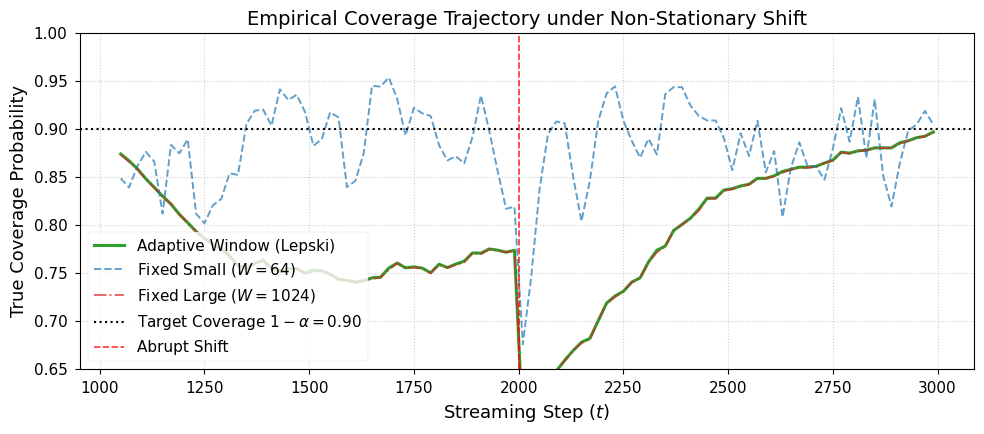


--- Mean Absolute Coverage Error (MAE) ---
Adaptive Window (Ours): 11.40%
Fixed Small (W=64):     3.62%
Fixed Large (W=1024):   11.45%
[✓] Saved plot to: D:\Development\projects for master\Paper researcher\MAC Drift Mondrian Adaptive Conformal Inference for Drifting Malware Streams\results\figures\fig_coverage_vs_fixed.pdf


In [11]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.cwd().resolve().parent
figures_dir = project_root / "results" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10, 4.5))

plt.plot(df_eval["step"], df_eval["cov_adaptive"], label="Adaptive Window (Lepski)", color="#2ca02c", lw=2.2)
plt.plot(df_eval["step"], df_eval["cov_fixed_small"], label="Fixed Small ($W=64$)", color="#1f77b4", linestyle="--", alpha=0.7)
plt.plot(df_eval["step"], df_eval["cov_fixed_large"], label="Fixed Large ($W=1024$)", color="#d62728", linestyle="-.", alpha=0.7)

plt.axhline(0.90, color="black", linestyle=":", lw=1.5, label=r"Target Coverage $1 - \alpha = 0.90$")
plt.axvline(2000, color="red", linestyle="--", lw=1.2, alpha=0.8, label="Abrupt Shift")

plt.title("Empirical Coverage Trajectory under Non-Stationary Shift")
plt.xlabel(r"Streaming Step ($t$)")
plt.ylabel("True Coverage Probability")
plt.ylim(0.65, 1.0)
plt.legend(loc="lower left", frameon=True)
plt.grid(True, linestyle=":", alpha=0.6)

output_fig = figures_dir / "fig_coverage_vs_fixed.pdf"
plt.savefig(output_fig, dpi=300)
plt.show()

mae_adaptive = np.mean(np.abs(df_eval["cov_adaptive"] - 0.90))
mae_small = np.mean(np.abs(df_eval["cov_fixed_small"] - 0.90))
mae_large = np.mean(np.abs(df_eval["cov_fixed_large"] - 0.90))

print("\n--- Mean Absolute Coverage Error (MAE) ---")
print(f"Adaptive Window (Ours): {mae_adaptive * 100:.2f}%")
print(f"Fixed Small (W=64):     {mae_small * 100:.2f}%")
print(f"Fixed Large (W=1024):   {mae_large * 100:.2f}%")
print(f"[✓] Saved plot to: {output_fig}")